# What happens when the bus cannot drive to plan?

Every result this project has produced rests on an assumption that is about to
stop being true.

`run_trial` builds one `GraphTravelModel` and gives it to both the planning
side and the simulation, so **estimate and ground truth are the same
function**. A schedule certified feasible is executed exactly as projected. The
service window is a promise the bus is structurally incapable of breaking:
once a request is accepted, its pickup happens when the plan said it would.

That is why the only way to fail a passenger today is to **refuse them up
front**. Every metric we track is shaped by that. The refusal rate is the
failure rate.

CARLA dissolves this on day one. Traffic, signals and vehicle dynamics make
the drive take a time nobody predicted, and a new failure mode appears that
the mock simulation cannot currently express: a request is accepted, promised
a pickup inside the window, and then **delivered late**.

This notebook opens that gap deliberately, on the planar map, before the
integration phase rather than during it.

## Why this matters for the routing work specifically

Because it may not affect L0 and L1 equally, and there is a mechanism to
expect it will not.

L1's whole job is to tighten the schedule. It relocates requests to squeeze
out slack that the insertion order left lying around, and the L1 ablation
measured exactly that: a 12% ride-time improvement bought by packing riders in
a better order. **The slack it removes is also the buffer that absorbs
execution error.**

If that is right, the headline result of the last month — L1 wins on every
metric, p < 0.001 — could weaken, vanish, or reverse under realistic driving.
Better to know that now than to discover it halfway through a CARLA
integration, having built on it.

## How the noise works

`NoisyTravelModel` multiplies each leg's graph travel time by a lognormal
factor with median 1.0, and is handed to the **backend alone**. The policy
keeps planning against the clean graph, which is what makes the two diverge.

Three properties of that choice matter for reading the results:

- **Median 1.0**, so `sigma` reads as a spread rather than a slowdown. A
  typical leg still takes the time the graph predicts.
- **Right-skewed**, so the *mean* factor exceeds 1.0. A bus loses more to
  congestion than it wins back by running early, and delay accumulates along a
  route instead of cancelling out. A symmetric noise model would have let
  early legs pay for late ones and flattered both policies.
- **One draw per leg driven.** `SimulationBackend` asks for a leg's duration
  when the leg begins and caches it until arrival, so noise does not re-roll
  underneath a moving bus.

!!! note "The two policies see the same weather, not the same draws"
    Both columns at a given sigma use the same seeded generator, but they
    drive different routes and therefore consume the stream differently. They
    face statistically identical conditions rather than leg-for-leg identical
    ones. Pairing is on **demand**, which is shared exactly.

## The measurement problem, and how it is handled

There is an interaction to be careful about. The policy plans against a
**750 s service window**, but the backend independently cancels any request
still waiting after **900 s** (`max_wait_s`, the abandonment threshold). These
are different quantities that both bound waiting.

So a broken promise shows up in one of two places depending on how badly it
was broken:

| what happened | where it appears |
|---|---|
| picked up after the promised 750 s, before 900 s | **breach rate** |
| still waiting at 900 s | **cancelled**, i.e. served fraction falls |

Reading either alone understates the harm, so both are reported side by side
throughout. `LOAD` is kept identical to every previous campus experiment so
the sigma = 0 column reproduces the existing baseline exactly; changing the
abandonment threshold to make measurement tidier would have broken that.

!!! warning "The breach rate does not start at zero"
    A noiseless bus can *still* miss the window, and a probe run measured
    around **1-2% of fulfilled requests** breaching at sigma = 0, overrunning
    by a few tens of seconds.

    The cause is the **progress fallback**. When the policy can schedule
    nothing at all it abandons the schedule and drives to the nearest pending
    pickup, deliberately ignoring the window — it exists to stop the bus
    stalling, and a late pickup beats no pickup. That path boards passengers
    whose deadline has already passed.

    So the guarantee was never "no accepted request is picked up late"; it is
    "no request is accepted *into a schedule* that predicts a late pickup".
    The floor is small and it is a design decision, not a defect — but it
    means **the signal here is the rise above the sigma = 0 row, not the
    absolute level**, and it makes the sigma = 0 row a control rather than a
    zero.

## The questions, and what would settle them

### Q1 — does lateness appear at all, and how fast?

Breach rate and served fraction against sigma, for L0.

Measured against the sigma = 0 control, which is **not zero** — see the
warning above.

- **Breaches rise steeply** → the service window is not robust to execution
  error, and the guarantee the policy offers is much weaker in practice than
  on paper. This would be the single most important thing to fix before
  CARLA.
- **Breaches stay near zero while served falls** → the harm routes entirely
  through abandonment. Passengers are not delivered late, they are simply lost
  — which is a coverage problem, and one the policy could in principle detect
  and re-plan around.
- **Both stay flat to sigma = 0.3** → the schedule carries enough natural
  slack to absorb realistic error, and this whole concern is unfounded. A
  genuinely good outcome, and worth knowing with the same confidence.

### Q2 — is L1 more fragile than L0?

The question this notebook exists for. Compare the L1-minus-L0 delta at each
sigma against the delta at sigma = 0.

- **L1's advantage shrinks as sigma grows** → confirms the slack hypothesis.
  L1 buys ride quality by spending the buffer that absorbs error, so its gain
  is partly an artefact of perfect execution. The size of the shrinkage says
  whether L1 survives CARLA as a good idea.
- **L1's advantage holds** → reordering is robust, and the result transfers.
  This is the outcome that would let us set routing aside with confidence.
- **L1's advantage *grows*** → would mean a well-ordered route is inherently
  more tolerant of delay, presumably because it spends less time far from
  where it needs to be next. Plausible, and it would make L1 more valuable
  under CARLA than the current figures suggest, not less.

### Q3 — can `safety_factor` buy the robustness back?

`safety_factor` inflates travel estimates when testing feasibility, so the
policy plans as though driving were slower than the graph says. It has existed
in `WindowInsertionPolicy` since the beginning, was set to 1.25 exactly once
in an early notebook, and has **never been swept**. If noise hurts, this is
the knob that already exists to trade coverage for reliability.

Tested at sigma = 0.2 for both policies.

- **Breaches fall for a modest coverage cost** → there is a real tuning axis
  here, and CARLA planning should start from a value above 1.0.
- **Breaches barely move** → margin on individual legs is the wrong
  instrument, because delay compounds along a route rather than per leg. That
  would point at re-planning frequency instead, which is a structural change.

### Q4 — does the policy notice?

The bus re-plans on every stop arrival, re-anchoring on the real clock. So
after a slow leg it *knows* it is late, and its next plan is built from the
true position and time. Does that self-correction absorb the error, or does it
just re-promise from a worse starting point? Watch whether the breach rate
grows faster than linearly in sigma: compounding would suggest re-planning is
chasing a receding target rather than recovering.

In [1]:
%matplotlib inline
# Static comparison charts only, so the inline backend is all we need.

import statistics
import time
from typing import Callable

import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import Markdown, display

from src.algorithm.DispatchPolicy import DispatchPolicy
from src.algorithm.ReorderingInsertionPolicy import ReorderingInsertionPolicy
from src.algorithm.WindowInsertionPolicy import WindowInsertionPolicy
from src.experiment import TrialResult, compare_policies, run_trial
from src.map.PlanarMapProvider import PlanarMapProvider
from src.map.TransitGraph import TransitGraph
from src.map.graph import PlanarStreetGraph


def make_factory(
    policy_class: type, window: float, **policy_kwargs: object,
) -> Callable[[TransitGraph], DispatchPolicy]:
    """
    Build a policy factory with the given construction arguments.

    A named closure rather than a lambda, so the late-binding trap that bites
    list comprehensions cannot arise.
    :param policy_class: Policy to construct.
    :param window: Service window in seconds.
    :param policy_kwargs: Extra keyword arguments for the policy.
    :return: Callable taking a TransitGraph and returning a policy.
    """
    def factory(graph: TransitGraph) -> DispatchPolicy:
        return policy_class(graph, max_wait_s=window, **policy_kwargs)
    return factory

## 1. Configuration

### Why sigma is swept and not just switched on

A single "noisy" column would answer whether noise hurts but not how the harm
scales, and scaling is what tells us whether the concern is academic. 0.1 is
mild — most legs within 10% of prediction — and 0.3 is severe enough to stand
in for genuinely bad traffic. If the frontier is still intact at 0.3, the
question is closed.

### Choosing `N_TRIALS`

The headline metric here is a **proportion** (breach rate) measured over
roughly 200 requests per trial, so it resolves far more tightly per trial than
the ride-time metrics that set the trial count in previous notebooks. The
binding constraint is again max ride, at ±108 s per 200 paired trials.

**250** gives about ±97 s on max ride and, more importantly, a breach-rate
half-width well under a percentage point — which is the precision Q1 and Q2
actually need. Ride metrics land near ±6 s, comfortably below the 63.7 s
effect L1 is being tested for.

### Runtime

Measured, one trial per column at W750:

| | sigma 0 | 0.1 | 0.2 | 0.3 | 0.2 + safety 1.25 |
|---|---|---|---|---|---|
| L0 | 1.7 s | 1.8 s | 1.8 s | 1.9 s | 1.8 s |
| L1 | 5.9 s | 6.1 s | 6.3 s | 6.5 s | 6.2 s |

About 36 s per trial across all ten columns, so **roughly 2.5 hours** at 250
trials. The probe cell re-measures before the run commits.

Noise costs almost nothing on its own: it adds one `exp` and one normal draw
per leg. The cost is dominated by L1's repair, as everywhere else.

In [2]:
N_TRIALS = 250
BASE_SEED = 0

# The recommended operating point from the 800-trial baseline, and the window
# every promise below is measured against.
WINDOW = 750.0

# Sigma of the lognormal factor on executed travel time. 0.0 is the existing
# noiseless baseline and must reproduce it exactly.
SIGMAS: list[float] = [0.0, 0.1, 0.2, 0.3]

# The sigma at which the safety_factor question (Q3) is asked.
SAFETY_SIGMA = 0.2
SAFETY_FACTOR = 1.25

# run_trial kwargs matching every previous campus experiment. NOTE: max_wait_s
# here is the *backend's abandonment threshold* (900 s), a different quantity
# from WINDOW (750 s), which is the promise the policy plans against. Requests
# that break the promise by more than 150 s are cancelled rather than counted
# late — see the measurement note above.
LOAD = dict(
    max_requests=200, capacity=40, max_wait_s=900.0, commitment=0,
)

# retry_rejected is pinned off (now the default) so L1 differs from L0 by the
# repair pass alone.
L1_KWARGS = dict(n_passes=1, retry_rejected=False)

LEVELS: list[tuple[str, type, dict]] = [
    ("L0", WindowInsertionPolicy, {}),
    ("L1", ReorderingInsertionPolicy, L1_KWARGS),
]

BASE_POLICIES: list[tuple[str, Callable[[TransitGraph], DispatchPolicy]]] = [
    (level, make_factory(policy_class, WINDOW, **policy_kwargs))
    for level, policy_class, policy_kwargs in LEVELS
]

# The Q3 columns: identical policies, but planning against inflated travel
# estimates so schedules are built with margin to spare.
SAFETY_POLICIES: list[
    tuple[str, Callable[[TransitGraph], DispatchPolicy]]
] = [
    (level, make_factory(
        policy_class, WINDOW, safety_factor=SAFETY_FACTOR, **policy_kwargs
    ))
    for level, policy_class, policy_kwargs in LEVELS
]

print(f"window {WINDOW:.0f} s, abandonment {LOAD['max_wait_s']:.0f} s")
print(f"sigmas: {SIGMAS}, plus safety {SAFETY_FACTOR} at {SAFETY_SIGMA}")

window 750 s, abandonment 900 s
sigmas: [0.0, 0.1, 0.2, 0.3], plus safety 1.25 at 0.2


## 2. Shared map

Identical to every previous sweep — same `MAP_SEED`, same campus
configuration — so the sigma = 0 columns are directly comparable to
`baseline-c0.ipynb` and `reordering-l1-ablation.ipynb`.

In [3]:
MAP_SEED = 42

graph = PlanarStreetGraph.generate(
    n_seeds=17,
    bounds=(0.0, 0.0, 2000.0, 2000.0),
    seed=MAP_SEED,
    stop_density=0.5,
)

provider = PlanarMapProvider(graph)
print(f"{len(provider.get_stops())} bus stops on this map")

21 bus stops on this map


## 3. Cost check

One trial per column before committing. Noise should be nearly free; this
mostly confirms that nothing pathological happens when schedules start
slipping — for instance a bus that misses so many deadlines it re-plans into a
much longer schedule.

In [4]:
probe_costs: dict[str, float] = {}
for sigma in SIGMAS:
    for label, factory in BASE_POLICIES:
        start = time.perf_counter()
        run_trial(
            policy_factory=factory, graph=graph, seed=BASE_SEED,
            silent=True, travel_noise=sigma, **LOAD,
        )
        probe_costs[f"{label} s{sigma}"] = time.perf_counter() - start

for label, factory in SAFETY_POLICIES:
    start = time.perf_counter()
    run_trial(
        policy_factory=factory, graph=graph, seed=BASE_SEED,
        silent=True, travel_noise=SAFETY_SIGMA, **LOAD,
    )
    probe_costs[f"{label} safety"] = time.perf_counter() - start

lines = ["| Column | " + " | ".join(f"sigma {s}" for s in SIGMAS)
         + " | safety |",
         "| --- " * (len(SIGMAS) + 2) + "|"]
for label, _ in BASE_POLICIES:
    cells = " | ".join(
        f"{probe_costs[f'{label} s{sigma}']:.1f} s" for sigma in SIGMAS
    )
    lines.append(
        f"| {label} | {cells} | {probe_costs[f'{label} safety']:.1f} s |"
    )
projected_s = N_TRIALS * sum(probe_costs.values())
lines.append("")
lines.append(
    f"Projected total ({N_TRIALS} trials x {len(probe_costs)} columns): "
    f"**{projected_s / 3600:.1f} hours**"
)
display(Markdown("\n".join(lines)))

| Column | sigma 0.0 | sigma 0.1 | sigma 0.2 | sigma 0.3 | safety |
| --- | --- | --- | --- | --- | --- |
| L0 | 1.0 s | 0.8 s | 1.0 s | 1.2 s | 1.1 s |
| L1 | 3.5 s | 4.2 s | 4.0 s | 5.1 s | 5.7 s |

Projected total (250 trials x 10 columns): **1.9 hours**

## 4. The run

`travel_noise` is a `run_trial` argument, not a policy argument, so it cannot
be a column in a single `compare_policies` call — every column in one call
shares its trial kwargs. Instead there is one call per sigma, all sharing
`BASE_SEED`.

That preserves pairing in both directions: trial *i* faces demand seeded
`BASE_SEED + i` in **every** column of **every** call, so L1 can be compared
against L0 at fixed sigma, and any column can be compared against its own
sigma = 0 counterpart.

In [5]:
# results[sigma][level] -> list of TrialResult
results: dict[float, dict[str, list[TrialResult]]] = {}

for sigma in SIGMAS:
    print(f"sigma = {sigma}")
    results[sigma] = compare_policies(
        policies=BASE_POLICIES,
        graph=graph,
        n_trials=N_TRIALS,
        base_seed=BASE_SEED,
        travel_noise=sigma,
        **LOAD,
    )

print(f"safety_factor = {SAFETY_FACTOR} at sigma = {SAFETY_SIGMA}")
safety_results = compare_policies(
    policies=SAFETY_POLICIES,
    graph=graph,
    n_trials=N_TRIALS,
    base_seed=BASE_SEED,
    travel_noise=SAFETY_SIGMA,
    **LOAD,
)

sigma = 0.0


L0:   0%|          | 0/250 [00:00<?, ?it/s]

L1:   0%|          | 0/250 [00:00<?, ?it/s]

sigma = 0.1


L0:   0%|          | 0/250 [00:00<?, ?it/s]

L1:   0%|          | 0/250 [00:00<?, ?it/s]

... (5 outputs left out)

L1:   0%|          | 0/250 [00:00<?, ?it/s]

safety_factor = 1.25 at sigma = 0.2


L0:   0%|          | 0/250 [00:00<?, ?it/s]

L1:   0%|          | 0/250 [00:00<?, ?it/s]

## 5. Does the promise break? (Q1, Q4)

`breach rate` is the share of **fulfilled** requests whose wait exceeded the
750 s the policy planned against. `served` is the counterweight: requests that
would have breached by more than 150 s were cancelled at the abandonment
threshold instead, so a falling served fraction hides breaches that never got
the chance to be counted.

Read the two columns together. Either one alone understates the harm.

In [6]:
def breach_rate(trial: TrialResult, window: float = WINDOW) -> float | None:
    """
    Share of fulfilled requests picked up later than the policy promised.
    :param trial: One trial's results.
    :param window: The service window planned against, in seconds.
    :return: Percentage of fulfilled requests breaching it, or None when
        nobody was carried.
    """
    if not trial.wait_times:
        return None
    late = sum(1 for wait in trial.wait_times if wait > window)
    return 100.0 * late / len(trial.wait_times)


def worst_breach(trial: TrialResult, window: float = WINDOW) -> float | None:
    """
    How far past the promise the worst-served passenger was picked up.
    :param trial: One trial's results.
    :param window: The service window planned against, in seconds.
    :return: Seconds of overrun, 0.0 when nothing breached, None when nobody
        was carried.
    """
    if not trial.wait_times:
        return None
    return max(0.0, max(trial.wait_times) - window)


def served_pp(trial: TrialResult) -> float | None:
    """
    Served fraction as percentage points, or None when undefined.
    :param trial: One trial's results.
    :return: Served fraction x 100, or None.
    """
    if trial.kpi.served_fraction is None:
        return None
    return 100.0 * trial.kpi.served_fraction


def max_ride(trial: TrialResult) -> float | None:
    """
    Longest ride in one trial, or None when nobody was carried.
    :param trial: One trial's results.
    :return: Maximum ride time in seconds, or None.
    """
    return max(trial.ride_times) if trial.ride_times else None


def mean_of(
    trials: list[TrialResult],
    extract: Callable[[TrialResult], float | None],
) -> float:
    """
    Mean of one metric across trials, ignoring trials that lack it.
    :param trials: Per-trial results.
    :param extract: Maps a TrialResult to the scalar.
    :return: The mean, or NaN when no trial defined it.
    """
    values = [v for t in trials if (v := extract(t)) is not None]
    return statistics.fmean(values) if values else float("nan")


lines = [
    "| sigma | level | breach rate | worst overrun | served | mean wait "
    "| mean ride |",
    "| --- | --- | --- | --- | --- | --- | --- |",
]
for sigma in SIGMAS:
    for level, _ in BASE_POLICIES:
        trials = results[sigma][level]
        lines.append(
            f"| {sigma} | {level} "
            f"| {mean_of(trials, breach_rate):.2f} % "
            f"| {mean_of(trials, worst_breach):.0f} s "
            f"| {mean_of(trials, served_pp):.1f} % "
            f"| {mean_of(trials, lambda r: r.kpi.mean_wait_time):.0f} s "
            f"| {mean_of(trials, lambda r: r.kpi.mean_ride_time):.0f} s |"
        )
display(Markdown("\n".join(lines)))
display(Markdown(
    "*The sigma = 0 rows are the control, not a zero. They must reproduce "
    "the known W750 baseline (91.1% served, 596 s mean ride), and they carry "
    "a small non-zero breach rate from the progress fallback — see the "
    "warning above. Every reading below is the **rise over that row**.*"
))

# Breach rate above the noiseless floor, which is what noise is responsible
# for. Reported separately because the absolute rate includes fallback
# boardings that have nothing to do with execution error.
lines = [
    "**Breaches attributable to noise** (rate minus the sigma = 0 control)",
    "",
    "| sigma | L0 | L1 |",
    "| --- | --- | --- |",
]
for sigma in SIGMAS:
    cells = []
    for level, _ in BASE_POLICIES:
        floor = mean_of(results[0.0][level], breach_rate)
        cells.append(
            f"{mean_of(results[sigma][level], breach_rate) - floor:+.2f} pp"
        )
    lines.append(f"| {sigma} | " + " | ".join(cells) + " |")
display(Markdown("\n".join(lines)))

| sigma | level | breach rate | worst overrun | served | mean wait | mean ride |
| --- | --- | --- | --- | --- | --- | --- |
| 0.0 | L0 | 2.31 % | 110 s | 90.9 % | 425 s | 596 s |
| 0.0 | L1 | 2.36 % | 112 s | 91.7 % | 422 s | 505 s |
| 0.1 | L0 | 3.65 % | 111 s | 91.1 % | 417 s | 607 s |
| 0.1 | L1 | 3.77 % | 109 s | 91.6 % | 414 s | 499 s |
| 0.2 | L0 | 4.85 % | 115 s | 90.5 % | 418 s | 629 s |
| 0.2 | L1 | 4.88 % | 116 s | 91.2 % | 412 s | 505 s |
| 0.3 | L0 | 5.60 % | 120 s | 89.1 % | 417 s | 653 s |
| 0.3 | L1 | 5.81 % | 121 s | 89.7 % | 413 s | 517 s |

*The sigma = 0 rows are the control, not a zero. They must reproduce the known W750 baseline (91.1% served, 596 s mean ride), and they carry a small non-zero breach rate from the progress fallback — see the warning above. Every reading below is the **rise over that row**.*

**Breaches attributable to noise** (rate minus the sigma = 0 control)

| sigma | L0 | L1 |
| --- | --- | --- |
| 0.0 | +0.00 pp | +0.00 pp |
| 0.1 | +1.34 pp | +1.41 pp |
| 0.2 | +2.54 pp | +2.51 pp |
| 0.3 | +3.30 pp | +3.44 pp |

## 6. Is L1 more fragile than L0? (Q2)

Paired L1-minus-L0 differences at each sigma. The row to watch is not any
single delta but how the deltas *move* as sigma grows.

If L1's advantage is partly an artefact of perfect execution, it shrinks here.
If it holds, reordering survives contact with unreliable driving and the
result transfers to CARLA.

In [7]:
def paired_delta(
    baseline: list[TrialResult],
    treatment: list[TrialResult],
    extract: Callable[[TrialResult], float | None],
) -> tuple[float, float, float]:
    """
    Mean per-trial difference (treatment - baseline) with a CI and a p-value.

    Trials are paired by index, which is meaningful because every column
    shares BASE_SEED, so trial i faced the same demand sequence throughout.
    :param baseline: Per-trial results for the reference column.
    :param treatment: Per-trial results for the column being tested.
    :param extract: Maps a TrialResult to the scalar being compared, or None
        when that trial does not define it.
    :return: (mean difference, 95% CI half-width, two-sided paired p-value).
        The last two are NaN with fewer than two usable pairs.
    """
    pairs = [
        (before, after)
        for base_trial, treat_trial in zip(baseline, treatment)
        if (before := extract(base_trial)) is not None
        and (after := extract(treat_trial)) is not None
    ]
    if not pairs:
        return float("nan"), float("nan"), float("nan")

    differences = [after - before for before, after in pairs]
    mean_difference = statistics.fmean(differences)
    if len(differences) < 2:
        return mean_difference, float("nan"), float("nan")

    half_width = (
        stats.t.ppf(0.975, len(differences) - 1)
        * statistics.stdev(differences)
        / len(differences) ** 0.5
    )
    p_value = float(stats.ttest_rel(
        [after for _, after in pairs],
        [before for before, _ in pairs],
    ).pvalue)
    return mean_difference, half_width, p_value


# (display name, extractor, direction that counts as an improvement)
_MetricSpec = tuple[str, Callable[[TrialResult], float | None], str]

METRICS: list[_MetricSpec] = [
    ("Served (pp)", served_pp, "higher"),
    ("Breach rate (pp)", breach_rate, "lower"),
    ("Mean wait (s)", lambda r: r.kpi.mean_wait_time, "lower"),
    ("Mean ride (s)", lambda r: r.kpi.mean_ride_time, "lower"),
    ("Max ride (s)", max_ride, "lower"),
]

for metric_name, extract, better in METRICS:
    lines = [
        f"**{metric_name}** — L1 minus L0, paired within each sigma", "",
        "| sigma | L0 | L1 | delta | p |",
        "| --- | --- | --- | --- | --- |",
    ]
    for sigma in SIGMAS:
        l0_trials = results[sigma]["L0"]
        l1_trials = results[sigma]["L1"]
        delta, half_width, p_value = paired_delta(
            l0_trials, l1_trials, extract
        )
        improved = delta > 0 if better == "higher" else delta < 0
        mark = "**" if p_value < 0.05 and improved else ""
        lines.append(
            f"| {sigma} | {mean_of(l0_trials, extract):.2f} "
            f"| {mean_of(l1_trials, extract):.2f} "
            f"| {mark}{delta:+.2f} ± {half_width:.2f}{mark} "
            f"| {p_value:.4f} |"
        )
    display(Markdown("\n".join(lines)))

**Served (pp)** — L1 minus L0, paired within each sigma

| sigma | L0 | L1 | delta | p |
| --- | --- | --- | --- | --- |
| 0.0 | 90.89 | 91.67 | **+0.79 ± 0.26** | 0.0000 |
| 0.1 | 91.11 | 91.57 | **+0.46 ± 0.32** | 0.0057 |
| 0.2 | 90.54 | 91.17 | **+0.64 ± 0.31** | 0.0001 |
| 0.3 | 89.08 | 89.74 | **+0.66 ± 0.34** | 0.0002 |

**Breach rate (pp)** — L1 minus L0, paired within each sigma

| sigma | L0 | L1 | delta | p |
| --- | --- | --- | --- | --- |
| 0.0 | 2.31 | 2.36 | +0.05 ± 0.19 | 0.5646 |
| 0.1 | 3.65 | 3.77 | +0.12 ± 0.26 | 0.3529 |
| 0.2 | 4.85 | 4.88 | +0.03 ± 0.28 | 0.8335 |
| 0.3 | 5.60 | 5.81 | +0.20 ± 0.30 | 0.1837 |

**Mean wait (s)** — L1 minus L0, paired within each sigma

| sigma | L0 | L1 | delta | p |
| --- | --- | --- | --- | --- |
| 0.0 | 425.21 | 422.10 | **-3.11 ± 2.48** | 0.0140 |
| 0.1 | 417.22 | 414.24 | **-2.98 ± 2.59** | 0.0243 |
| 0.2 | 417.51 | 411.64 | **-5.87 ± 2.54** | 0.0000 |
| 0.3 | 417.10 | 412.58 | **-4.52 ± 2.80** | 0.0016 |

**Mean ride (s)** — L1 minus L0, paired within each sigma

| sigma | L0 | L1 | delta | p |
| --- | --- | --- | --- | --- |
| 0.0 | 596.44 | 504.55 | **-91.89 ± 7.84** | 0.0000 |
| 0.1 | 607.32 | 499.09 | **-108.23 ± 8.10** | 0.0000 |
| 0.2 | 628.91 | 504.53 | **-124.38 ± 9.54** | 0.0000 |
| 0.3 | 652.63 | 516.80 | **-135.83 ± 9.62** | 0.0000 |

**Max ride (s)** — L1 minus L0, paired within each sigma

| sigma | L0 | L1 | delta | p |
| --- | --- | --- | --- | --- |
| 0.0 | 3084.92 | 2834.51 | **-250.41 ± 113.15** | 0.0000 |
| 0.1 | 3217.11 | 2859.39 | **-357.72 ± 113.80** | 0.0000 |
| 0.2 | 3448.04 | 2956.11 | **-491.93 ± 144.83** | 0.0000 |
| 0.3 | 3537.86 | 3121.52 | **-416.34 ± 139.00** | 0.0000 |

## 7. The degradation curves (Q1, Q2, Q4)

Left: how fast the promise breaks. Right: whether L1's advantage survives.

Curvature in the left panel is the Q4 signal — a breach rate growing faster
than linearly in sigma means delay is compounding faster than re-planning can
recover it.

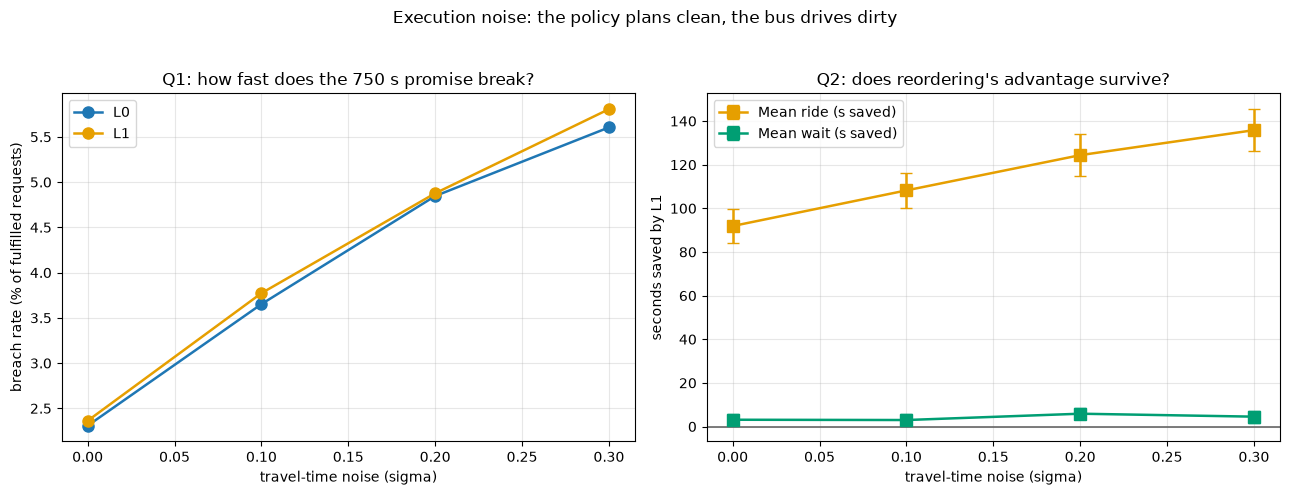

In [8]:
# Colourblind-safe pair, validated for CVD separation.
L0_COLOUR = "#1f77b4"
L1_COLOUR = "#e69f00"
LEVEL_COLOURS = {"L0": L0_COLOUR, "L1": L1_COLOUR}

fig, (left, right) = plt.subplots(1, 2, figsize=(13, 5))

for level, _ in BASE_POLICIES:
    left.errorbar(
        SIGMAS,
        [mean_of(results[s][level], breach_rate) for s in SIGMAS],
        marker="o", markersize=8, linewidth=1.8,
        color=LEVEL_COLOURS[level], label=level,
    )
left.set_xlabel("travel-time noise (sigma)")
left.set_ylabel("breach rate (% of fulfilled requests)")
left.set_title("Q1: how fast does the 750 s promise break?")
left.grid(True, alpha=0.3)
left.legend()

# Q2: L1's advantage on each headline metric, as a function of sigma.
ADVANTAGE: list[_MetricSpec] = [
    ("Mean ride (s saved)", lambda r: r.kpi.mean_ride_time, "lower"),
    ("Mean wait (s saved)", lambda r: r.kpi.mean_wait_time, "lower"),
]
for (name, extract, _), colour in zip(ADVANTAGE, (L1_COLOUR, "#009e73")):
    deltas, errors = [], []
    for sigma in SIGMAS:
        delta, half_width, _ = paired_delta(
            results[sigma]["L0"], results[sigma]["L1"], extract
        )
        # Plotted as a saving, so "up" means "L1 still helps".
        deltas.append(-delta)
        errors.append(half_width)
    right.errorbar(
        SIGMAS, deltas, yerr=errors, marker="s", markersize=8,
        linewidth=1.8, capsize=4, color=colour, label=name,
    )
right.axhline(0, color="0.4", linewidth=1.2)
right.set_xlabel("travel-time noise (sigma)")
right.set_ylabel("seconds saved by L1")
right.set_title("Q2: does reordering's advantage survive?")
right.grid(True, alpha=0.3)
right.legend()

fig.suptitle(
    "Execution noise: the policy plans clean, the bus drives dirty"
)
fig.tight_layout(rect=(0.0, 0.0, 1.0, 0.95))
plt.show()

## 8. Can margin buy it back? (Q3)

`safety_factor=1.25` makes the policy test feasibility against travel
estimates inflated by 25%, so it only accepts requests it could still serve on
a slow day. The expected trade is fewer breaches for lower coverage.

Compared against the same policies at the same sigma without the margin.

In [9]:
lines = [
    f"**sigma = {SAFETY_SIGMA}, with and without safety_factor "
    f"{SAFETY_FACTOR}**", "",
    "| level | safety | breach rate | worst overrun | served | mean ride |",
    "| --- | --- | --- | --- | --- | --- |",
]
for level, _ in BASE_POLICIES:
    for tag, trials in (
        ("1.0", results[SAFETY_SIGMA][level]),
        (f"{SAFETY_FACTOR}", safety_results[level]),
    ):
        lines.append(
            f"| {level} | {tag} "
            f"| {mean_of(trials, breach_rate):.2f} % "
            f"| {mean_of(trials, worst_breach):.0f} s "
            f"| {mean_of(trials, served_pp):.1f} % "
            f"| {mean_of(trials, lambda r: r.kpi.mean_ride_time):.0f} s |"
        )
display(Markdown("\n".join(lines)))

lines = [
    "**Paired effect of the safety factor**", "",
    "| level | metric | delta | p |",
    "| --- | --- | --- | --- |",
]
for level, _ in BASE_POLICIES:
    for metric_name, extract, _ in [
        ("Breach rate (pp)", breach_rate, "lower"),
        ("Served (pp)", served_pp, "higher"),
        ("Mean ride (s)", lambda r: r.kpi.mean_ride_time, "lower"),
    ]:
        delta, half_width, p_value = paired_delta(
            results[SAFETY_SIGMA][level], safety_results[level], extract
        )
        lines.append(
            f"| {level} | {metric_name} "
            f"| {delta:+.2f} ± {half_width:.2f} | {p_value:.4f} |"
        )
display(Markdown("\n".join(lines)))
display(Markdown(
    "*A useful safety factor shows a negative breach delta bought with a "
    "small negative served delta. If served falls hard and breaches barely "
    "move, per-leg margin is the wrong instrument — delay compounds along a "
    "route, not within a leg.*"
))

**sigma = 0.2, with and without safety_factor 1.25**

| level | safety | breach rate | worst overrun | served | mean ride |
| --- | --- | --- | --- | --- | --- |
| L0 | 1.0 | 4.85 % | 115 s | 90.5 % | 629 s |
| L0 | 1.25 | 1.95 % | 104 s | 90.6 % | 736 s |
| L1 | 1.0 | 4.88 % | 116 s | 91.2 % | 505 s |
| L1 | 1.25 | 2.20 % | 108 s | 91.0 % | 571 s |

**Paired effect of the safety factor**

| level | metric | delta | p |
| --- | --- | --- | --- |
| L0 | Breach rate (pp) | -2.89 ± 0.25 | 0.0000 |
| L0 | Served (pp) | +0.10 ± 0.31 | 0.5132 |
| L0 | Mean ride (s) | +106.90 ± 12.21 | 0.0000 |
| L1 | Breach rate (pp) | -2.68 ± 0.25 | 0.0000 |
| L1 | Served (pp) | -0.21 ± 0.28 | 0.1387 |
| L1 | Mean ride (s) | +66.90 ± 7.24 | 0.0000 |

*A useful safety factor shows a negative breach delta bought with a small negative served delta. If served falls hard and breaches barely move, per-leg margin is the wrong instrument — delay compounds along a route, not within a leg.*

## What to look for

**Regression check first.** The sigma = 0 rows must reproduce W750 from
`baseline-c0.ipynb` (91.1% served, 596 s mean ride). They will *not* show a
zero breach rate — expect roughly 1-2%, from the progress fallback boarding
passengers whose deadline has already passed. That floor is the control
everything else is read against; what would be a bug is the served fraction or
mean ride disagreeing with the baseline, which would mean `travel_noise=0.0`
is not returning the shared planning model as it should.

**A finding that falls out of the control row.** The window is already
breached without any execution noise at all, purely because the fallback
ignores it. Nobody has counted that before, because until now there was no
reason to look at lateness among *accepted* requests. It is small, and it is a
deliberate trade — a late pickup beats a stalled bus — but "the service window
is a hard guarantee" is not quite what the code does, and the docs should say
so however this experiment turns out.

**Q1 — the breach curve.** This is the number that says whether the service
window means anything under realistic driving.

- *Steep rise* → the guarantee is much weaker in practice than on paper, and
  that is the headline finding. It would mean the current refusal-rate framing
  of "failure" is incomplete: the policy is also failing people it accepted,
  and we have never counted them.
- *Flat, with served falling* → harm routes through abandonment rather than
  lateness. Different problem, more tractable: the passenger is lost rather
  than badly served, and a policy could detect the impending miss and
  re-plan.
- *Both flat to sigma = 0.3* → the schedule absorbs realistic error and this
  concern is closed. Worth stating loudly in the docs, because it removes a
  risk from the CARLA phase.

**Q2 — the fragility comparison, which is why this notebook exists.**

- *L1's advantage shrinks with sigma* → the slack hypothesis is confirmed and
  the L1 result is partly an artefact of perfect execution. Whether that
  changes the recommendation depends on how much shrinks: half of a 63.7 s
  saving is still a saving. But it would mean every L1 figure in the docs
  needs a caveat, and it would raise the priority of re-measuring under CARLA
  early rather than late.
- *Holds flat* → reordering is robust. Combined with a null on the `n_passes`
  notebook, that is a clean place to stop routing work: L1 is finished, it
  works, and it survives unreliable execution.
- *Grows* → the more interesting outcome, and not implausible. A well-ordered
  route keeps the bus nearer to wherever it must be next, so a lost minute
  costs less. If this happens, L1 is worth *more* under CARLA than the current
  figures suggest, and the L2 question reopens on stronger grounds.

**Q3 — the safety factor.** Mostly actionable rather than interesting. If it
works, CARLA planning starts above 1.0 and we have a knob. If it does not,
that is itself informative: it would mean the error accumulates along a route
faster than per-leg margin can absorb, pointing at re-planning frequency — and
re-planning currently fires only on stop arrival, which is exactly the
structural assumption CARLA puts under most pressure.

**What this cannot tell us.** Lognormal per-leg noise with a fixed sigma is a
crude stand-in for traffic. Real congestion is spatially and temporally
correlated: the same junction is slow for everyone, all afternoon. Correlated
delay is harder to absorb than independent delay, because re-planning cannot
route around a problem that follows the bus. So treat these results as a
**lower bound on the harm**, not an estimate of it.